In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,Dropout
from sklearn.model_selection import train_test_split
from tensorflow.keras.optimizers import SGD

I0000 00:00:1793618105.801774   46206 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793618105.802132   46206 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793618105.834068   46206 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793618107.012330   46206 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
train_path = "Downloads/DL/cifar10/train.csv"
test_path = "Downloads/DL/cifar10/test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

In [3]:
train_df.head(5)

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [4]:
test_df.head(5)

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3062,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071
0,158,159,165,166,160,156,162,159,158,159,...,130,123,145,167,182,175,145,124,129,110
1,235,231,232,232,232,232,232,232,232,232,...,108,117,123,133,141,153,163,178,191,199
2,158,158,139,132,166,182,187,193,199,205,...,45,46,44,44,43,52,37,8,3,7
3,155,167,176,190,177,166,168,166,170,179,...,52,55,70,103,105,72,53,50,52,50
4,65,70,48,30,23,40,44,45,45,40,...,102,127,156,139,131,130,147,136,146,117


In [5]:
X = train_df.drop("label",axis = 1).values
y = train_df["label"].values

print("Input Shape : " , X.shape)
print("Output Shape : " , y.shape)
print("Unique labels : " , np.unique(y))

Input Shape :  (50000, 3072)
Output Shape :  (50000,)
Unique labels :  [0 1 2 3 4 5 6 7 8 9]


In [6]:
X = X.astype("float32")/255.0
X_test = test_df.to_numpy(dtype="float32") / 255.0

In [7]:
X_train , X_val , y_train , y_val = train_test_split(
    X , y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Traning Data : " , X_train.shape)
print("Validation data : " , X_val.shape)

Traning Data :  (40000, 3072)
Validation data :  (10000, 3072)


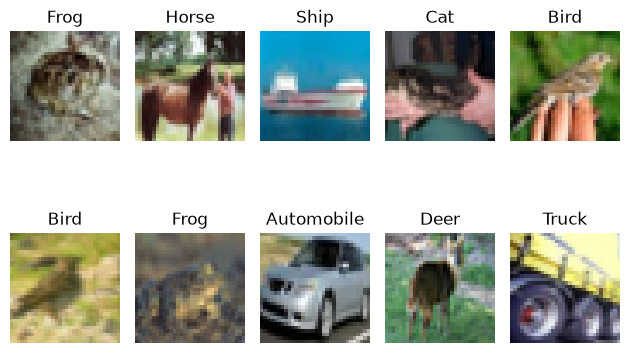

In [8]:
classes = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
           'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
for i in range(10):
    image = X_train[i].reshape(3, 32, 32).transpose(1, 2, 0)

    plt.subplot(2, 5, i+1)
    plt.imshow(image)
    plt.title(classes[int(y_train[i])])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(512,activation="relu"),
    Dense(256,activation="relu"),
    Dense(10,activation="softmax")
])

model.summary()

E0000 00:00:1793618111.881044   46206 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793618111.913303   46206 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [11]:
history = model.fit(
    X_train,y_train,
    epochs = 10,
    batch_size = 64,
    validation_data = (X_val,y_val),
    verbose = 1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.3198 - loss: 1.8869 - val_accuracy: 0.3835 - val_loss: 1.7301
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.3843 - loss: 1.7116 - val_accuracy: 0.3999 - val_loss: 1.6686
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.4185 - loss: 1.6227 - val_accuracy: 0.4335 - val_loss: 1.5946
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4419 - loss: 1.5602 - val_accuracy: 0.4286 - val_loss: 1.5844
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4570 - loss: 1.5208 - val_accuracy: 0.4632 - val_loss: 1.5162
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4714 - loss: 1.4795 - val_accuracy: 0.4542 - val_loss: 1.5672
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.4829 - loss: 1.4506 - val_accuracy: 0.4555 - val_loss: 1.5434
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.4927 - loss: 1.4231 - val_accuracy: 0.

In [12]:
loss,accuracy = model.evaluate(X_val,y_val,verbose = 0 )

print("acurracy" , accuracy)
print("loss : " , loss)

acurracy 0.48539999127388
loss :  1.464953064918518


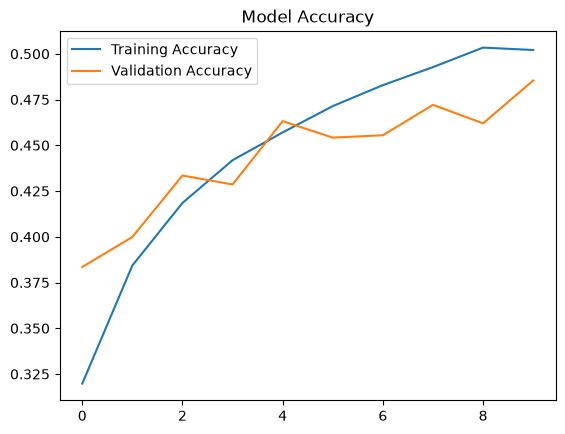

In [13]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.legend()

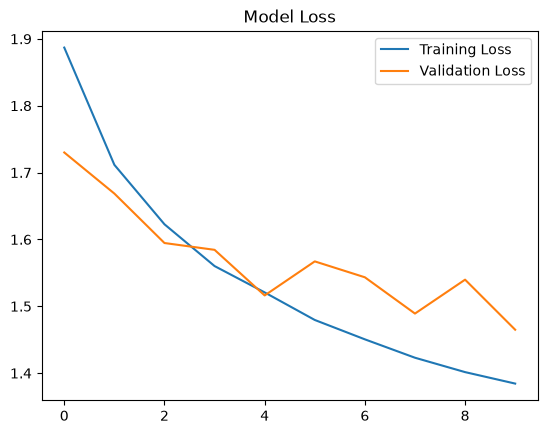

In [14]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.legend()

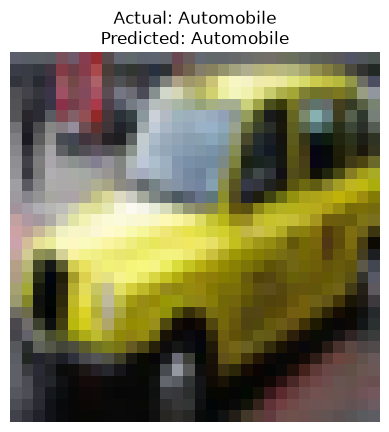

In [15]:
n = np.random.randint(0, len(X_test))

prediction = model.predict(X_test[n].reshape(1, 3072), verbose=0)

plt.imshow(X_test[n].reshape(3, 32, 32).transpose(1, 2, 0))
plt.title("Actual: " + classes[int(y_val[n])] +
          "\nPredicted: " + classes[np.argmax(prediction)])
plt.axis('off')
plt.show()